# Workshop 3 — Segmentación de clientes con Clustering

**Curso:** Fundamentos de Aprendizaje Automático — EAFIT — 2026-2 | **Profesor:** Yomin Estiven Jaramillo Múnera

**Dataset:** [Mall Customer Segmentation Data](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) — `data/Mall_Customers.csv` (en la raíz del repo)

**Pregunta del taller:** ¿en cuántos grupos "naturales" se dividen los clientes del centro comercial y qué caracteriza a cada uno?

---

| Fases | Contenido | Responsable |
|---|---|---|
| 0 a 4 (puntos 2 a 6) | Datos, K-Means, Agglomerative, DBSCAN y PCA 3D | Kevin Pabón Niño |
| 5 a 10 (puntos 7 a 13) | Comparación, perfilado y clasificador | Gerónimo Montes Acebedo |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

# Para que los resultados sean reproducibles
random_state = 42

RUTA = "../../data/Mall_Customers.csv"

## Fase 0 — Carga y preprocesamiento

### 2.1 Exploración inicial

Antes de agrupar nada, miramos cómo vienen los datos.

In [2]:
df = pd.read_csv(RUTA)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


**Ojo con el nombre de la columna:** el enunciado habla de `Genre`, pero la versión actual del CSV en Kaggle la trae como `Gender`. La renombramos a `Genre` para que el resto del notebook use los mismos nombres del enunciado.

In [4]:
df = df.rename(columns={"Gender": "Genre"})
df.columns.tolist()

['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

In [5]:
# Nulos y duplicados
print("Nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("CustomerID repetidos:", df["CustomerID"].duplicated().sum())

Nulos por columna:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Filas duplicadas: 0
CustomerID repetidos: 0


In [6]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [7]:
df["Genre"].value_counts()

Genre
Female    112
Male       88
Name: count, dtype: int64

Veamos cómo se reparten las tres variables numéricas.

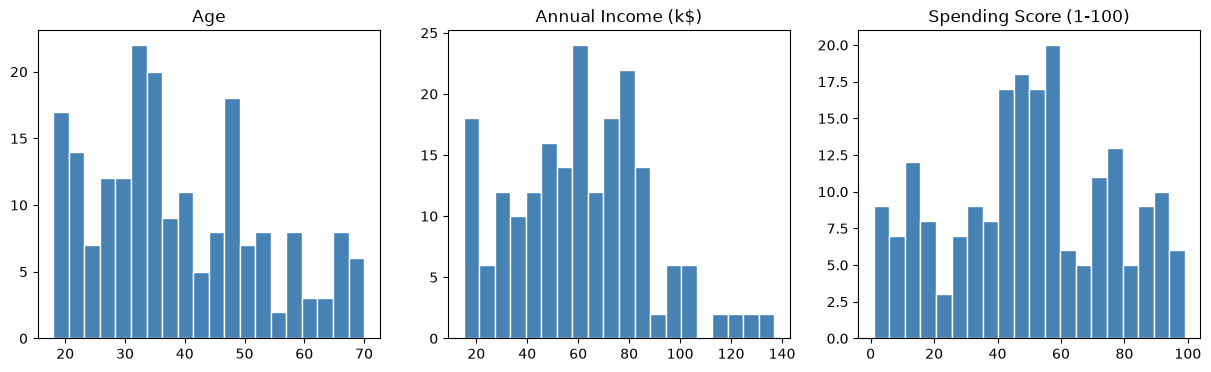

In [8]:
numericas = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numericas):
    ax.hist(df[col], bins=20, color="steelblue", edgecolor="white")
    ax.set_title(col)
plt.show()

Y la gráfica que más nos interesa para segmentar: ingreso contra gasto.

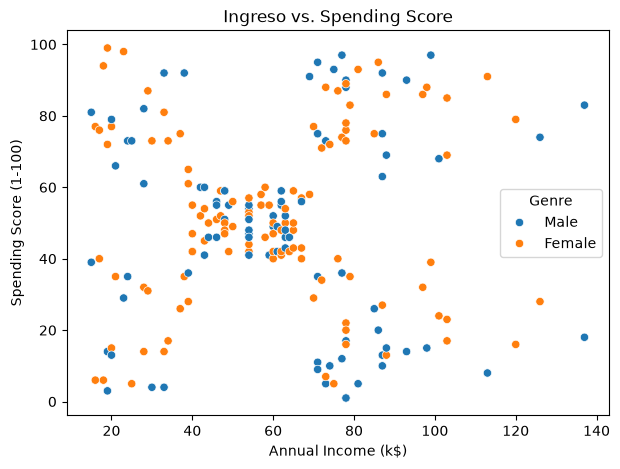

In [9]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Genre")
plt.title("Ingreso vs. Spending Score")
plt.show()

In [10]:
df[numericas].corr().round(2)

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.00,-0.01,-0.33
Annual Income (k$),-0.01,1.00,0.01
Spending Score (1-100),-0.33,0.01,1.00


### Respuestas — Exploración

**¿Hay valores nulos?** No. Tampoco hay filas duplicadas ni clientes repetidos. Son 200 clientes y 5 columnas, así que no hay nada que limpiar.

**¿Qué tipo tiene cada columna?**
- `Genre` es texto: es la única **categórica** (112 mujeres y 88 hombres).
- `Age`, `Annual Income (k$)` y `Spending Score (1-100)` son números enteros: son las **numéricas**.
- `CustomerID` también es un número, pero es solo un identificador.

**Otras cosas que vimos:**
- Edades entre 18 y 70 años (promedio 39), ingresos entre 15 y 137 mil dólares, y gasto entre 1 y 99.
- En la gráfica de ingreso vs. gasto se ven a simple vista unas **5 nubes de clientes**: una en el centro y una en cada esquina. Es buena señal de que sí hay grupos.
- El ingreso no tiene relación con el gasto (correlación 0.01): ganar más no significa gastar más. La edad sí tiene algo que ver: los mayores tienden a gastar un poco menos (-0.33).

### 2.2 Selección de variables

`CustomerID` es solo un número de fila, no dice nada del cliente. La quitamos.

In [11]:
df = df.drop(columns=["CustomerID"])
df.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


### 2.3 Codificación de `Genre`

`Genre` tiene solo dos valores (Male / Female) y no hay un orden entre ellos. Con dos categorías basta mapearla a 0 y 1 con `.map()`: el resultado es igual a un One-Hot quedándonos con una sola columna, y no agrega columnas de más.

In [12]:
df["Genre_encoded"] = df["Genre"].map({"Male": 0, "Female": 1})
df[["Genre", "Genre_encoded"]].value_counts()

Genre   Genre_encoded
Female  1                112
Male    0                 88
Name: count, dtype: int64

### 2.4 Estandarización

In [13]:
features = ["Genre_encoded", "Age", "Annual Income (k$)", "Spending Score (1-100)"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# Antes: cada variable en su propia escala
print("Rango antes de escalar:")
print(df[features].agg(["min", "max", "std"]).round(2))

# Después: todas con media 0 y desviación 1
print("\nDespués de escalar:")
print(pd.DataFrame(X_scaled, columns=features).agg(["mean", "std"]).round(2))

Rango antes de escalar:
     Genre_encoded    Age  Annual Income (k$)  Spending Score (1-100)
min            0.0  18.00               15.00                    1.00
max            1.0  70.00              137.00                   99.00
std            0.5  13.97               26.26                   25.82

Después de escalar:
      Genre_encoded  Age  Annual Income (k$)  Spending Score (1-100)
mean           -0.0 -0.0                -0.0                    -0.0
std             1.0  1.0                 1.0                     1.0


**¿Por qué estandarizar?**

Estos tres algoritmos agrupan por distancia: dos clientes están en el mismo grupo si sus números se parecen. Si no escalamos, manda la variable con números más grandes.

En la tabla de arriba se ve: el ingreso va de 15 a 137, la edad de 18 a 70 y `Genre_encoded` solo de 0 a 1. Sin escalar, una diferencia de 50 mil dólares pesaría mucho más que una diferencia de 50 años, y el género casi no contaría. Después de escalar, todas quedan con media 0 y desviación 1, y pesan lo mismo.

## Fase 1 — K-Means

K-Means necesita que le digamos cuántos grupos (`k`) queremos. Pone `k` centros y va moviéndolos hasta que cada cliente quede lo más cerca posible del centro de su grupo.

Probamos `k` de 2 a 10 (el enunciado pide mínimo hasta 8; fuimos un poco más lejos para ver si el Silhouette deja de subir) y guardamos dos cosas por cada uno:
- **Inercia:** qué tan apretados quedan los grupos (más bajo = más apretados).
- **Silhouette:** qué tan bien separado está cada grupo de los demás (va de -1 a 1, más alto = mejor).

In [14]:
ks = range(2, 11)
inertias = []
siluetas_kmeans = []

for k in ks:
    model = KMeans(n_clusters=k, random_state=random_state, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    siluetas_kmeans.append(silhouette_score(X_scaled, labels))

tabla_kmeans = pd.DataFrame({"k": ks, "Inercia": inertias, "Silhouette Score": siluetas_kmeans})
tabla_kmeans.round(3)

,k,Inercia,Silhouette Score
0,2,588.803,0.252
1,3,476.788,0.260
2,4,388.718,0.298
3,5,331.310,0.304
4,6,276.412,0.331
5,7,236.205,0.357
6,8,199.750,0.388
7,9,174.235,0.403
8,10,152.030,0.421


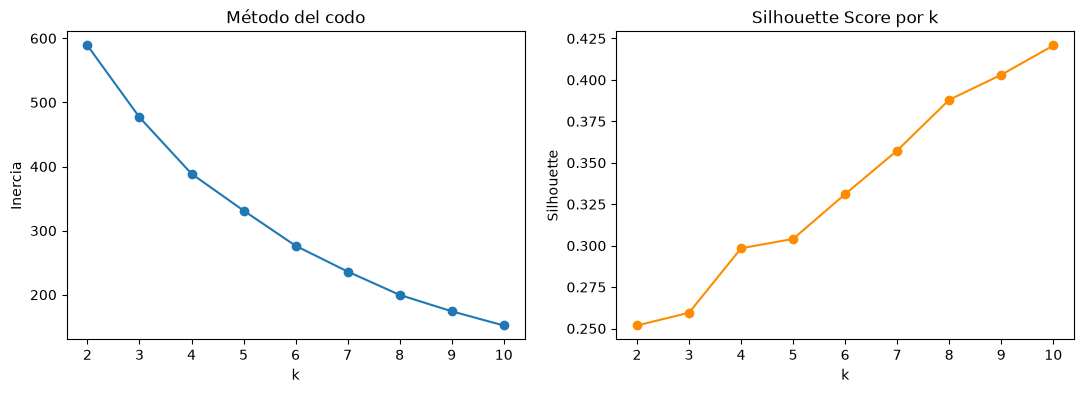

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(ks, inertias, marker="o")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inercia")

axes[1].plot(ks, siluetas_kmeans, marker="o", color="darkorange")
axes[1].set_title("Silhouette Score por k")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")

plt.show()

### Respuestas — K-Means

**1. ¿El codo coincide con el mejor Silhouette?** No del todo.
- El codo es suave, no hay un quiebre claro. Lo que sí se nota es que desde `k = 6` la inercia baja cada vez menos (baja 55 de 5 a 6, y después 40, 36, 25...).
- El Silhouette no tiene un pico: sube siempre, hasta 0.421 en `k = 10`. Con más grupos cada grupo es más pequeño y apretado, así que el puntaje sube casi solo. Aquí no sirve para elegir `k` por sí solo.

**2. ¿Qué `k` elegimos?** `k = 6`.
- Es donde el codo empieza a aplanarse y el Silhouette da un salto (de 0.304 a 0.331).
- Los 6 grupos tienen tamaños parecidos (entre 23 y 41 clientes) y, mirando los promedios de abajo, se pueden describir con palabras: por ejemplo, un grupo de ingreso alto que gasta mucho y otro de ingreso alto que gasta poco.
- Con 8 a 10 grupos el puntaje es mejor, pero salen grupos muy pequeños que no le sirven a un centro comercial para hacer campañas.

**Algo que notamos:** varios grupos son solo de mujeres o solo de hombres (`Genre_encoded` en 1.0 o 0.0). Al escalar, el género pesa igual que las otras variables y K-Means lo usa mucho para separar.

In [16]:
k_kmeans = 6

kmeans = KMeans(n_clusters=k_kmeans, random_state=random_state, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)

print("Clientes por cluster:", np.unique(labels_kmeans, return_counts=True))
print("Silhouette:", round(silhouette_score(X_scaled, labels_kmeans), 3))

Clientes por cluster: (array([0, 1, 2, 3, 4, 5], dtype=int32), array([41, 38, 34, 35, 23, 29]))
Silhouette: 0.331


In [17]:
# Promedio de cada variable por cluster (en unidades reales), solo para entender qué separó K-Means
df.assign(Cluster=labels_kmeans).groupby("Cluster")[features].mean().round(1)

,Genre_encoded,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,1.0,50.6,49.7,40.1
1,0.0,28.1,58.3,71.3
2,1.0,26.0,39.5,59.5
3,0.0,55.6,52.8,36.2
4,0.9,32.1,90.0,81.4
5,0.6,36.5,89.5,18.0


## Fase 2 — Clustering jerárquico aglomerativo

Aquí cada cliente empieza siendo su propio grupo, y en cada paso se juntan los dos grupos más parecidos. El dendrograma muestra ese proceso: entre más alta la línea vertical, más distintos eran los grupos que se unieron.

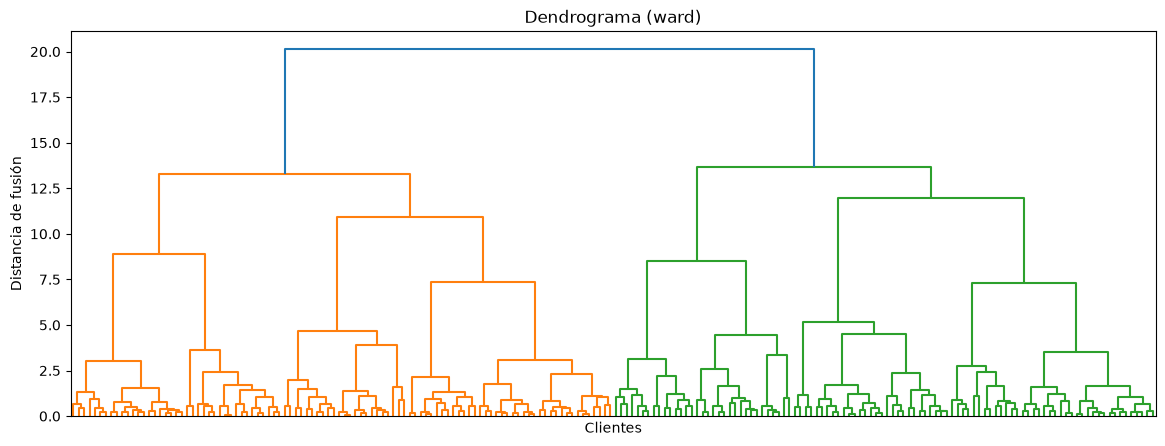

In [18]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True)
plt.title("Dendrograma (ward)")
plt.xlabel("Clientes")
plt.ylabel("Distancia de fusión")
plt.show()

In [19]:
siluetas_agg = []

for k in ks:
    model_k = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels_k = model_k.fit_predict(X_scaled)
    siluetas_agg.append(silhouette_score(X_scaled, labels_k))

tabla_agg = pd.DataFrame({"k": ks, "Silhouette Score": siluetas_agg})
tabla_agg.round(3)

,k,Silhouette Score
0,2,0.242
1,3,0.248
2,4,0.263
3,5,0.287
4,6,0.310
5,7,0.346
6,8,0.379
7,9,0.392
8,10,0.418


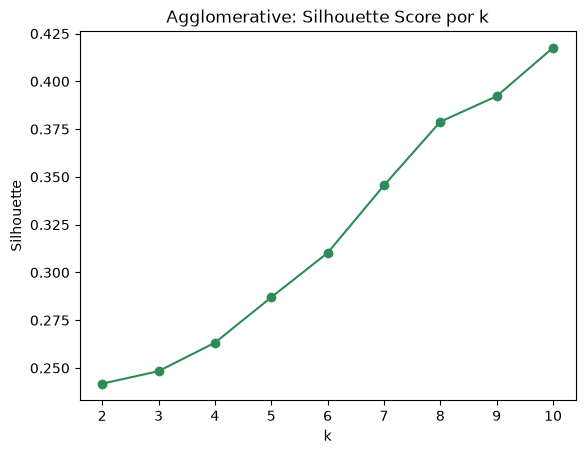

In [20]:
plt.plot(ks, siluetas_agg, marker="o", color="seagreen")
plt.title("Agglomerative: Silhouette Score por k")
plt.xlabel("k")
plt.ylabel("Silhouette")
plt.show()

### Respuestas — Agglomerative

**¿Cuántos grupos sugiere el dendrograma?**
- La unión más alta (a una altura de 20) parte a los clientes en **2 grupos grandes**. Es el salto más grande.
- Si cortamos más abajo, alrededor de 10, hay un tramo largo sin uniones y quedan **6 grupos**.

**¿Coincide con el mejor Silhouette?** No. Pasa lo mismo que en K-Means: el puntaje sube siempre y el mejor es `k = 10` (0.418). Y `k = 2`, que el dendrograma marca tan claro, tiene el peor puntaje (0.242).

**Elegimos `k = 6`** (Silhouette 0.310): coincide con el corte del dendrograma en 10 y con lo que elegimos en K-Means, así podemos comparar los dos métodos en igualdad de condiciones. Los grupos tienen entre 23 y 39 clientes.

In [21]:
k_agg = 6

agg = AgglomerativeClustering(n_clusters=k_agg, linkage="ward")
labels_agg = agg.fit_predict(X_scaled)

print("Clientes por cluster:", np.unique(labels_agg, return_counts=True))
print("Silhouette:", round(silhouette_score(X_scaled, labels_agg), 3))

Clientes por cluster: (array([0, 1, 2, 3, 4, 5]), array([39, 38, 33, 38, 29, 23]))
Silhouette: 0.31


## Fase 3 — DBSCAN

DBSCAN no pide el número de grupos. Busca zonas donde hay muchos clientes juntos:
- `eps`: el radio en el que se buscan vecinos.
- `min_samples`: cuántos vecinos hacen falta para decir "aquí hay una zona densa".

Los clientes que no caen en ninguna zona densa quedan como **ruido** (etiqueta `-1`).

Como en la clase, primero miramos el gráfico de k-distancias para tener una idea de qué `eps` tiene sentido.

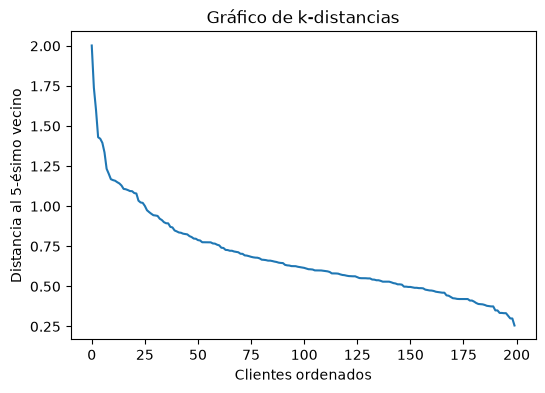

In [22]:
min_pts = 5

neighbors = NearestNeighbors(n_neighbors=min_pts).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])[::-1]

plt.figure(figsize=(6, 4))
plt.plot(k_dist)
plt.xlabel("Clientes ordenados")
plt.ylabel(f"Distancia al {min_pts}-ésimo vecino")
plt.title("Gráfico de k-distancias")
plt.show()

Ahora probamos la grilla del enunciado. Para el Silhouette quitamos el ruido, y si quedan menos de 2 grupos no se puede calcular (queda vacío).

In [23]:
resultados = []

for eps in [0.3, 0.5, 0.7, 0.9, 1.1]:
    for min_samples in [3, 5, 8, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        mask = labels != -1
        if n_clusters >= 2:
            score = silhouette_score(X_scaled[mask], labels[mask])
        else:
            score = np.nan

        resultados.append([eps, min_samples, n_clusters, n_noise, score])

tabla_dbscan = pd.DataFrame(resultados, columns=["eps", "min_samples", "N° clusters", "N° ruido", "Silhouette Score"])
tabla_dbscan.round(3)

,eps,min_samples,N° clusters,N° ruido,Silhouette Score
0,0.3,3,14,144,0.629
1,0.3,5,1,194,NaN
2,0.3,8,0,200,NaN
3,0.3,10,0,200,NaN
4,0.5,3,18,49,0.475
5,0.5,5,9,105,0.540
6,0.5,8,2,169,0.709
7,0.5,10,2,178,0.769
8,0.7,3,9,14,0.132
9,0.7,5,7,37,0.277


Para verlo más fácil, la misma tabla en forma de cuadrícula (filas = `eps`, columnas = `min_samples`):

In [24]:
print("Número de clusters:")
print(tabla_dbscan.pivot(index="eps", columns="min_samples", values="N° clusters"))
print("\nPuntos de ruido:")
print(tabla_dbscan.pivot(index="eps", columns="min_samples", values="N° ruido"))

Número de clusters:
min_samples  3   5   8   10
eps                        
0.3          14   1   0   0
0.5          18   9   2   2
0.7           9   7   5   5
0.9           3   2   4   5
1.1           2   2   2   2

Puntos de ruido:
min_samples   3    5    8    10
eps                            
0.3          144  194  200  200
0.5           49  105  169  178
0.7           14   37   76  106
0.9            8   13   25   46
1.1            0    7   10   10


In [25]:
eps_dbscan = 0.9
min_samples_dbscan = 8

dbscan = DBSCAN(eps=eps_dbscan, min_samples=min_samples_dbscan)
labels_dbscan = dbscan.fit_predict(X_scaled)

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = list(labels_dbscan).count(-1)
mask = labels_dbscan != -1

print("Clusters encontrados:", n_clusters_dbscan)
print(f"Puntos de ruido: {n_noise_dbscan} ({n_noise_dbscan / len(labels_dbscan):.1%} del total)")
print("Clientes por etiqueta:", np.unique(labels_dbscan, return_counts=True))
print("Silhouette (sin ruido):", round(silhouette_score(X_scaled[mask], labels_dbscan[mask]), 3))

Clusters encontrados: 4
Puntos de ruido: 25 (12.5% del total)
Clientes por etiqueta: (array([-1,  0,  1,  2,  3]), array([ 25, 103,  10,  36,  26]))
Silhouette (sin ruido): 0.269


¿Cómo quedan hombres y mujeres dentro de cada grupo de DBSCAN?

In [26]:
pd.crosstab(labels_dbscan, df["Genre"])

Genre,Female,Male
row_0,,
-1,9,16
0,103,0
1,0,10
2,0,36
3,0,26


### Respuestas — DBSCAN

En el gráfico de k-distancias la curva se dobla más o menos entre 0.9 y 1.1, así que buscamos `eps` por esa zona. Elegimos **`eps = 0.9` y `min_samples = 8`**: no deja un solo grupo gigante ni deja a casi todos como ruido.

**1. ¿Cuántos clusters encontró?** 4.

**2. ¿Cuántos puntos quedaron como ruido?** 25 clientes (12.5 %).

**3. ¿Qué pasa al mover los parámetros?**
- **Si sube `eps`:** el radio es más grande, así que se juntan más clientes. Hay menos ruido y, al final, menos grupos. Con `min_samples = 5` el ruido pasa de 194 a 105, 37, 13 y 7 clientes. Con `eps = 1.1` todo termina en 2 grupos.
- **Si sube `min_samples`:** se pide más vecinos para formar un grupo, así que hay más ruido. El número de grupos depende: con `eps = 0.5` baja de 18 a 2, pero con `eps = 0.9` sube de 3 a 5 porque las zonas grandes se rompen en pedazos.

**Ojo:** los Silhouette más altos de la tabla (0.709 y 0.769 con `eps = 0.5`) engañan: dejan entre 169 y 178 clientes como ruido. Solo están midiendo a los pocos que quedaron.

**Lo que muestra la tabla de género:** ningún grupo mezcla hombres y mujeres. Las 103 mujeres quedan en un solo grupo y los hombres se reparten en 3. La razón: después de escalar, la distancia entre un hombre y una mujer solo en `Genre_encoded` es de casi 2, más que `eps`, así que nunca pueden ser vecinos. DBSCAN separa primero por género y después no logra partir el grupo de mujeres.

## Fase 4 — Visualización con PCA en 3D

Tenemos 4 variables y no se pueden dibujar 4 dimensiones. PCA las resume en 3 nuevas variables (PC1, PC2, PC3) que conservan la mayor parte de la información, y así podemos ver los tres métodos en el mismo espacio.

In [27]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada por cada componente:", pca.explained_variance_ratio_.round(3))
print("Varianza explicada acumulada:", round(pca.explained_variance_ratio_.sum(), 3))

Varianza explicada por cada componente: [0.337 0.262 0.233]
Varianza explicada acumulada: 0.832


**¿Cuánta información conservan las 3 componentes?**

Las 3 componentes conservan el **83.2 %** de la información (33.7 % + 26.2 % + 23.3 %). Alcanza para mirar los grupos, pero no para sacar conclusiones solo con la gráfica: se pierde un 17 %, y dos puntos que se ven pegados pueden estar separados en la parte que no vemos. Las decisiones las tomamos con las tablas; las gráficas son de apoyo.

In [28]:
def plot_clusters_3d(X_pca, labels, title):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    scatter = ax.scatter(
        X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
        c=labels,
        cmap="viridis",
        s=40
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(title)

    legend = ax.legend(*scatter.legend_elements(), title="Cluster")
    ax.add_artist(legend)

    plt.show()

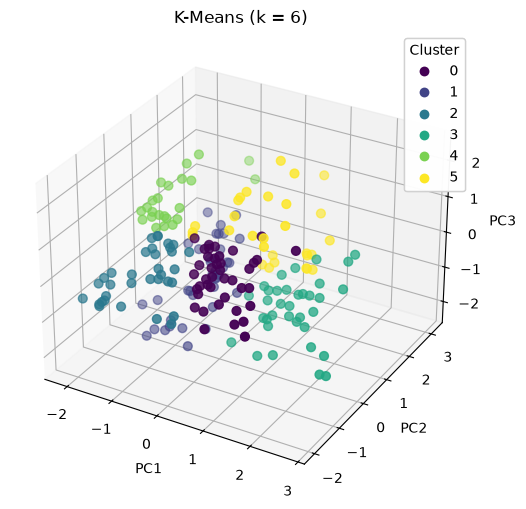

In [29]:
plot_clusters_3d(X_pca, labels_kmeans, f"K-Means (k = {k_kmeans})")

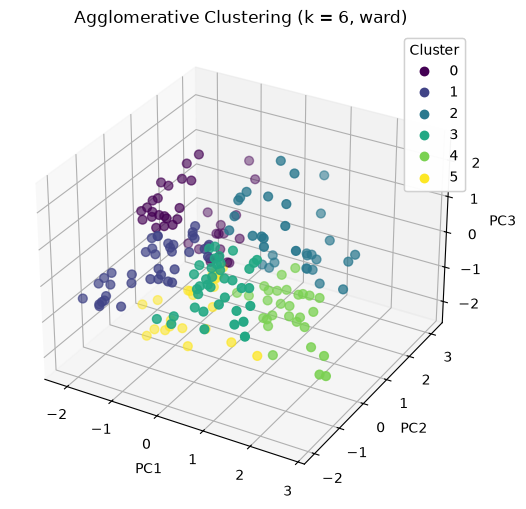

In [30]:
plot_clusters_3d(X_pca, labels_agg, f"Agglomerative Clustering (k = {k_agg}, ward)")

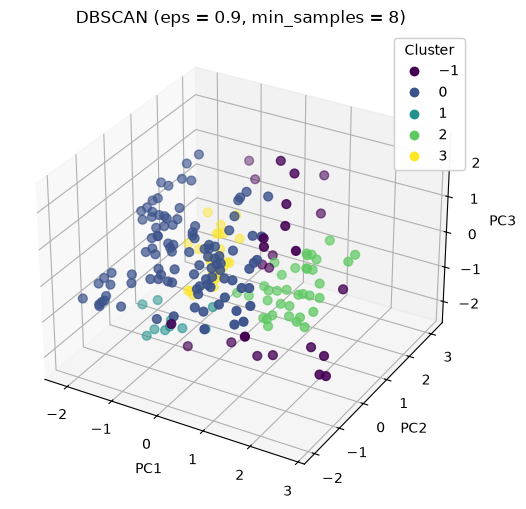

In [31]:
plot_clusters_3d(X_pca, labels_dbscan, f"DBSCAN (eps = {eps_dbscan}, min_samples = {min_samples_dbscan})")

### Lo que se ve en las gráficas

- **K-Means y Agglomerative se ven casi iguales:** los dos arman 6 grupos en zonas parecidas. Los colores no coinciden porque cada método numera los grupos a su manera.
- **Los grupos se tocan:** no hay islas bien separadas, sobre todo en el centro de la nube. Por eso el Silhouette se queda alrededor de 0.3.
- **DBSCAN se ve distinto:** el grupo 0 (todas las mujeres) ocupa casi toda la nube, y el ruido queda en las orillas.
- **El ruido de DBSCAN confunde:** el `-1` sale en morado como si fuera un grupo más. Para leerlo mejor habría que pintarlo aparte, por ejemplo en gris.

En resumen, K-Means y Agglomerative dan segmentos más útiles para este problema. DBSCAN funciona mejor cuando hay zonas muy densas separadas por espacios vacíos, y estos datos no son así. La comparación formal queda para la Fase 5.

---

## Entrega a la Fase 5 (Gerónimo)

Hasta aquí van las fases 0 a 4. Lo que queda listo en memoria para seguir:

| Variable | Qué tiene |
|---|---|
| `df` | Datos sin `CustomerID`, con `Genre` (texto) y `Genre_encoded` (0 = Male, 1 = Female) |
| `features`, `X_scaled`, `scaler` | Las 4 variables usadas y su versión estandarizada |
| `tabla_kmeans`, `tabla_agg`, `tabla_dbscan` | Las tablas de cada método |
| `labels_kmeans`, `k_kmeans` | Etiquetas de K-Means con el `k` elegido |
| `labels_agg`, `k_agg` | Etiquetas de Agglomerative (ward) con el `k` elegido |
| `labels_dbscan`, `eps_dbscan`, `min_samples_dbscan`, `n_noise_dbscan` | Etiquetas y parámetros de DBSCAN (ruido = `-1`) |
| `X_pca`, `plot_clusters_3d` | Proyección PCA 3D y la función para graficar |